# Task 1 - Exploratory Data Analysis: Adult Census Income

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../../datasets/census_income.csv", skipinitialspace=True)
df.shape

(48842, 15)

In [3]:
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## 1. First look

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       48842 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education-num   48842 non-null  int64
 5   marital-status  48842 non-null  str  
 6   occupation      48842 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital-gain    48842 non-null  int64
 11  capital-loss    48842 non-null  int64
 12  hours-per-week  48842 non-null  int64
 13  native-country  48842 non-null  str  
 14  income          48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 5.6 MB


In [5]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


**Observations**
- 15 columns: 6 numeric, 9 text. `info()` shows no missing values, but missing values may be hidden as `?`.
- `capital-gain` is 0 for at least 75% of people, max is 99999: probably a code, not a real amount.
- `age` max is 90 and `hours-per-week` max is 99: possible capped values, to check.
- `fnlwgt` is a census sampling weight, not a feature of the person.

## 2. Target

In [6]:
df["income"].value_counts()

income
<=50K     24720
<=50K.    12435
>50K       7842
>50K.      3845
Name: count, dtype: int64

In [7]:
df["income"] = df["income"].str.rstrip(".")
df["income"].value_counts()

income
<=50K    37155
>50K     11687
Name: count, dtype: int64

In [8]:
df["income_gt50k"] = (df["income"] == ">50K").astype(int)
df["income_gt50k"].mean()

np.float64(0.23928176569346055)

**Observations**
- `income` had 4 labels instead of 2: the trailing dot comes from the original test file appended to the train file.
- I removed the dot and created a binary target `income_gt50k` (1 = >50K).
- Only 23.9% earn more than 50K: the target is imbalanced (about 3 to 1).

## 3. Missing values

In [9]:
df.isna().sum()

age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
income            0
income_gt50k      0
dtype: int64

In [10]:
(df == "?").sum()

age                  0
workclass         2799
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        2809
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     857
income               0
income_gt50k         0
dtype: int64

In [11]:
import numpy as np

df = df.replace("?", np.nan)
df.isna().sum()

age                  0
workclass         2799
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        2809
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     857
income               0
income_gt50k         0
dtype: int64

In [12]:
has_missing = df.isna().any(axis=1)
print(has_missing.sum(), "rows with at least one missing value")
df.groupby(has_missing)["income_gt50k"].mean()

3620 rows with at least one missing value


False    0.247844
True     0.132320
Name: income_gt50k, dtype: float64

**Observations**
- Missing values were hidden as `?` in `workclass` (2799), `occupation` (2809) and `native-country` (857).
- 3620 rows (7.4%) have at least one missing value.
- These rows earn >50K only 13.2% of the time vs 24.8% for complete rows: missingness is not random.
- **Decision:** keep the rows and leave the values as NaN. Dropping them would remove mostly low-income people and bias the data.

## 4. Duplicates and column names

In [13]:
df.duplicated().sum()

np.int64(52)

In [14]:
df = df.drop_duplicates()
df.shape

(48790, 16)

In [15]:
df.columns = df.columns.str.replace("-", "_")
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education_num',
       'marital_status', 'occupation', 'relationship', 'race', 'sex',
       'capital_gain', 'capital_loss', 'hours_per_week', 'native_country',
       'income', 'income_gt50k'],
      dtype='str')

In [16]:
df = df.drop(columns=["fnlwgt"])
df.shape

(48790, 15)

**Observations**
- 52 duplicate rows (0.1%) removed after fixing the labels: 48790 rows left.
- Column names converted to snake_case (`education-num` -> `education_num`).
- `fnlwgt` dropped: it is a census sampling weight, not a property of the person.
- `education` and `education_num` carry the same information: a model should use only one of them.

## 5. Visual analysis

In [17]:
from pathlib import Path

FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

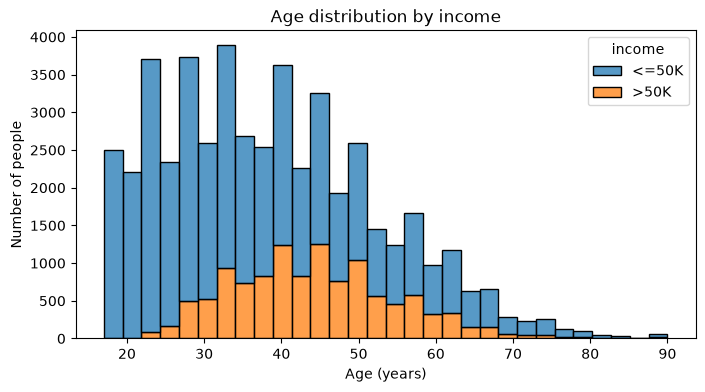

In [18]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="age", hue="income", bins=30, multiple="stack")
plt.title("Age distribution by income")
plt.xlabel("Age (years)")
plt.ylabel("Number of people")
plt.savefig(FIG_DIR / "fig01_age_by_income.png", dpi=120, bbox_inches="tight")
plt.show()

In [19]:
df.groupby("income")["age"].median()

income
<=50K    34.0
>50K     43.0
Name: age, dtype: float64

People earning >50K are older: median age 43 vs 34. Almost nobody under 25 earns >50K; high earners peak around 40-50 and decrease after 60 (retirement).

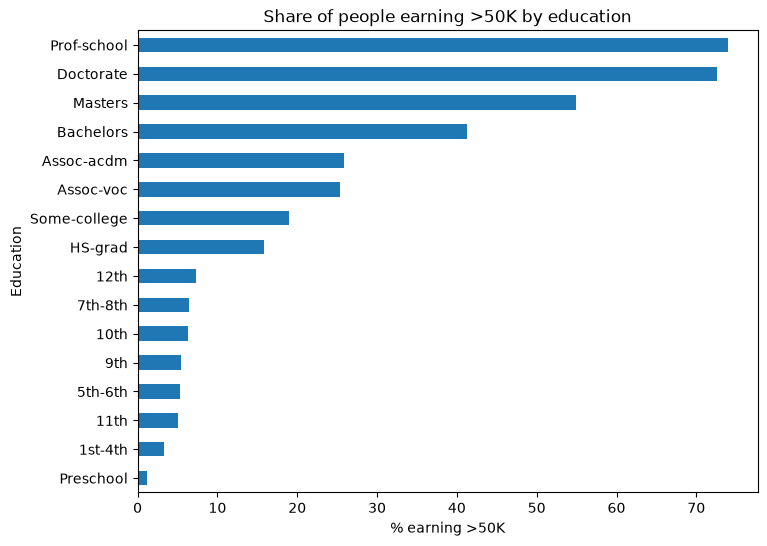

education
Preschool        1.2
1st-4th          3.3
11th             5.1
5th-6th          5.3
9th              5.4
10th             6.3
7th-8th          6.5
12th             7.3
HS-grad         15.9
Some-college    19.0
Assoc-voc       25.3
Assoc-acdm      25.8
Bachelors       41.3
Masters         54.9
Doctorate       72.6
Prof-school     74.0
Name: income_gt50k, dtype: float64

In [20]:
rate_edu = df.groupby("education")["income_gt50k"].mean().sort_values() * 100

plt.figure(figsize=(8, 6))
rate_edu.plot(kind="barh")
plt.title("Share of people earning >50K by education")
plt.xlabel("% earning >50K")
plt.ylabel("Education")
plt.savefig(FIG_DIR / "fig02_rate_by_education.png", dpi=120, bbox_inches="tight")
plt.show()
rate_edu.round(1)

Education is a strong driver: the share earning >50K grows from 1.2% (Preschool) to over 70% (Doctorate, Prof-school). The biggest jump is from HS-grad (~16%) to Bachelors (~41%).

In [21]:
(df.groupby("sex")["income_gt50k"].mean() * 100).round(1)

sex
Female    10.9
Male      30.4
Name: income_gt50k, dtype: float64

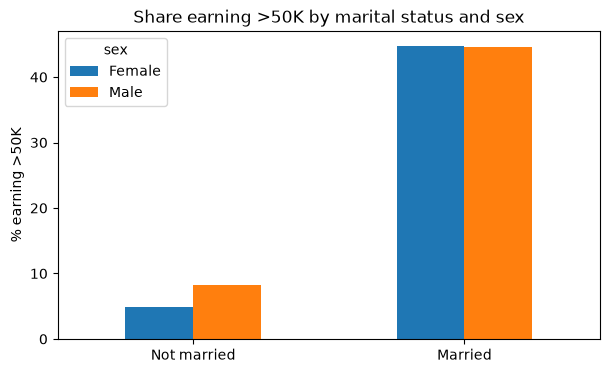

sex,Female,Male
Not married,4.8,8.2
Married,44.8,44.6


In [22]:
married = df["marital_status"] == "Married-civ-spouse"
rate_ms = df.groupby([married, "sex"])["income_gt50k"].mean().unstack() * 100
rate_ms.index = ["Not married", "Married"]

rate_ms.plot(kind="bar", figsize=(7, 4), rot=0)
plt.title("Share earning >50K by marital status and sex")
plt.xlabel("")
plt.ylabel("% earning >50K")
plt.savefig(FIG_DIR / "fig03_rate_by_marital_and_sex.png", dpi=120, bbox_inches="tight")
plt.show()
rate_ms.round(1)

In [23]:
(married.groupby(df["sex"]).mean() * 100).round(1)

sex
Female    15.3
Male      61.0
Name: marital_status, dtype: float64

Overall, men earn >50K far more often than women (30.4% vs 10.9%). But among married people the share is the same (about 45% for both), and among non-married people the gap is small (about 8% vs 5%). The overall gap comes mostly from composition: 61.0% of men are married vs only 15.3% of women, and married people earn much more. This is a correlation in this sample, not a cause.
